<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/zp/notebooks/Dataset_Loading_Parsing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 3.1 Data Loading and Parsing

In [7]:
import pandas as pd
import numpy as np
import json
import re
from pathlib import Path
from google.colab import drive
from pathlib import Path
import os

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/BT4222 Group Project/Microsoft MIND"
)

# Create a working folder if it does not already exist.
(PROJECT_DIR / "notebooks").mkdir(exist_ok=True)

# Set the directory from which relative paths are resolved.
os.chdir(PROJECT_DIR / "notebooks")

DATA_DIR = Path("../MINDsmall_train")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Load data

In [8]:
behaviour_cols = [
    "impression_id",
    "user_id",
    "time",
    "history",
    "impressions"
]

behaviours = pd.read_csv(
    DATA_DIR / "behaviors.tsv",
    sep="\t",
    header=None,
    names=behaviour_cols,
    dtype=str
)

news_cols = [
    "news_id", "category", "subcategory", "title", "abstract",
    "url", "title_entities", "abstract_entities"
]

news = pd.read_csv(
    DATA_DIR / "news.tsv",
    sep="\t",
    header=None,
    names=news_cols,
    dtype=str
)

print("Behaviours shape:", behaviours.shape)
display(behaviours.head())

print("News shape:", news.shape)
display(news.head())


Behaviours shape: (156965, 5)


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


News shape: (51282, 8)


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


### Parse timestamp

In [9]:
behaviours["time_parsed"] = pd.to_datetime(
    behaviours["time"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

behaviours["time_parsed"].describe()

,time_parsed
count,156965
mean,2019-11-12 09:36:00.672913920
min,2019-11-09 00:00:19
25%,2019-11-11 08:37:59
50%,2019-11-12 11:08:28
75%,2019-11-13 13:30:14
max,2019-11-14 23:59:13


### Parse reading history

In [10]:
behaviours["history_list"] = (
    behaviours["history"]
    .fillna("")
    .apply(lambda x: x.split() if x else [])
)

behaviours["history_length"] = behaviours["history_list"].str.len()

behaviours[["history", "history_list", "history_length"]].head()

,history,history_list,history_length
0,N55189 N42782 N34694 N45794 N18445 N63302 N104...,"[N55189, N42782, N34694, N45794, N18445, N6330...",9
1,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,"[N31739, N6072, N63045, N23979, N35656, N43353...",82
2,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,"[N10732, N25792, N7563, N21087, N41087, N5445,...",16
3,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,"[N45729, N2203, N871, N53880, N41375, N43142, ...",10
4,N10078 N56514 N14904 N33740,"[N10078, N56514, N14904, N33740]",4


### Parse impressions and labels

In [11]:
def parse_impressions(s):
    result = []

    for token in s.split():
        news_id, label = token.rsplit("-", 1)

        result.append({
            "news_id": news_id,
            "label": int(label)
        })

    return result


behaviours["parsed_impressions"] = behaviours["impressions"].apply(parse_impressions)

behaviours["num_candidates"] = behaviours["parsed_impressions"].str.len()

behaviours["num_clicked"] = behaviours["parsed_impressions"].apply(lambda x: sum(item["label"] for item in x))

behaviours["num_unclicked"] = (behaviours["num_candidates"] - behaviours["num_clicked"])

display(
    behaviours[
        [
            "impression_id",
            "user_id",
            "num_candidates",
            "num_clicked",
            "num_unclicked"
        ]
    ].head()
)

,impression_id,user_id,num_candidates,num_clicked,num_unclicked
0,1,U13740,2,1,1
1,2,U91836,11,1,10
2,3,U73700,36,1,35
3,4,U34670,4,1,3
4,5,U8125,69,1,68


### Load embedding files

In [12]:
def load_embedding(path, id_col):
    df = pd.read_csv(
        path,
        sep="\t",
        header=None
    )

    # Remove completely empty columns, e.g. caused by trailing tabs
    df = df.dropna(axis=1, how="all")

    embedding_dim = df.shape[1] - 1

    df.columns = (
        [id_col]
        + [f"emb_{i}" for i in range(embedding_dim)]
    )

    # Ensure embeddings are numeric
    embedding_cols = [c for c in df.columns if c != id_col]
    df[embedding_cols] = df[embedding_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    return df

In [13]:
entity_embeddings = load_embedding(
    DATA_DIR / "entity_embedding.vec",
    "entity_id"
)

relation_embeddings = load_embedding(
    DATA_DIR / "relation_embedding.vec",
    "relation_id"
)

print("Entity embeddings shape:", entity_embeddings.shape)
print("Relation embeddings shape:", relation_embeddings.shape)

display(entity_embeddings.head())

Entity embeddings shape: (26904, 101)
Relation embeddings shape: (1091, 101)


,entity_id,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,...,emb_90,emb_91,emb_92,emb_93,emb_94,emb_95,emb_96,emb_97,emb_98,emb_99
0,Q41,-0.063388,-0.181451,0.057501,-0.091254,-0.076217,-0.052525,0.050500,-0.224871,-0.018145,...,-0.051949,0.001861,0.124535,-0.151043,-0.263698,-0.103607,0.020007,-0.101157,-0.091567,0.035234
1,Q1860,0.060958,0.069934,0.015832,0.079471,-0.023362,-0.125007,-0.043618,0.134063,-0.121691,...,-0.070713,-0.014287,0.013578,0.099977,0.012199,-0.141138,0.056129,-0.133727,0.025795,0.051448
2,Q39631,-0.093106,-0.052002,0.020556,-0.020801,0.043180,-0.072321,0.000910,0.028156,0.176303,...,-0.124472,-0.086840,-0.078992,-0.062712,0.051117,-0.184307,0.127637,-0.144866,0.044690,0.013498
3,Q30,-0.115737,-0.179113,0.102739,-0.112469,-0.101853,-0.177516,0.015860,-0.092626,0.086708,...,0.005893,0.080511,-0.000085,-0.089968,-0.083486,-0.149992,-0.053031,-0.136071,-0.029001,0.174155
4,Q60,-0.051036,-0.165637,0.132802,-0.089949,-0.146637,-0.142246,0.103853,-0.129651,0.096265,...,-0.002713,0.078628,0.003711,-0.058953,-0.154067,-0.117159,-0.031614,-0.140451,0.001288,0.140350


### Parse news entities

In [14]:
def parse_entities(x):
    if pd.isna(x) or x == "":
        return []

    try:
        parsed = json.loads(x)

        if isinstance(parsed, list):
            return parsed

        return None

    except (json.JSONDecodeError, TypeError):
        return None

In [15]:
news["title_entities_parsed"] = (
    news["title_entities"].apply(parse_entities)
)

news["abstract_entities_parsed"] = (
    news["abstract_entities"].apply(parse_entities)
)

### Derived features

In [16]:
news["num_title_entities"] = (
    news["title_entities_parsed"]
    .apply(lambda x: len(x) if isinstance(x, list) else np.nan)
)

news["num_abstract_entities"] = (
    news["abstract_entities_parsed"]
    .apply(lambda x: len(x) if isinstance(x, list) else np.nan)
)

news["title_length"] = (
    news["title"]
    .fillna("")
    .str.split()
    .str.len()
)

news["abstract_length"] = (
    news["abstract"]
    .fillna("")
    .str.split()
    .str.len()
)

## Data Quality and Missing Values

In [17]:
def missing_summary(df):
    summary = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100
    })

    return summary.sort_values(
        "missing_pct",
        ascending=False
    )

In [18]:
print("Behaviors missing values")
display(missing_summary(
    behaviours[behaviour_cols]
))

print("News missing values")
display(missing_summary(
    news[news_cols]
))

Behaviors missing values


,missing_count,missing_pct
history,3238,2.06288
impression_id,0,0.00000
user_id,0,0.00000
time,0,0.00000
impressions,0,0.00000


News missing values


,missing_count,missing_pct
abstract,2666,5.198705
abstract_entities,4,0.007800
title_entities,3,0.005850
news_id,0,0.000000
title,0,0.000000
subcategory,0,0.000000
category,0,0.000000
url,0,0.000000


### Duplicates

In [19]:
print("Duplicate behavior rows:",
      behaviours.duplicated(subset=behaviour_cols).sum())

print("Duplicate impression IDs:",
      behaviours["impression_id"].duplicated().sum())

print("Duplicate news rows:",
      news.duplicated(subset=news_cols).sum())

print("Duplicate news IDs:",
      news["news_id"].duplicated().sum())

print("Duplicate entity IDs:",
      entity_embeddings["entity_id"].duplicated().sum())

print("Duplicate relation IDs:",
      relation_embeddings["relation_id"].duplicated().sum())

Duplicate behavior rows: 0
Duplicate impression IDs: 0
Duplicate news rows: 0
Duplicate news IDs: 0
Duplicate entity IDs: 0
Duplicate relation IDs: 0


### Identifier validity

In [20]:
invalid_users = (
    ~behaviours["user_id"]
    .fillna("")
    .str.match(r"^U\d+$")
)

invalid_news = (
    ~news["news_id"]
    .fillna("")
    .str.match(r"^N\d+$")
)

print("Invalid user IDs:", invalid_users.sum())
print("Invalid news IDs:", invalid_news.sum())

Invalid user IDs: 0
Invalid news IDs: 0


### Timestamp validity

In [21]:
print(
    "Unparseable timestamps:",
    behaviours["time_parsed"].isna().sum()
)

print(
    "Timestamp range:",
    behaviours["time_parsed"].min(),
    "to",
    behaviours["time_parsed"].max()
)

Unparseable timestamps: 0
Timestamp range: 2019-11-09 00:00:19 to 2019-11-14 23:59:13


### Impression-format validation

In [22]:
impression_pattern = re.compile(r"^N\d+-[01]$")

invalid_impression_tokens = []

for impression_string in behaviours["impressions"].dropna():

    for token in impression_string.split():

        if not impression_pattern.match(token):
            invalid_impression_tokens.append(token)

print(
    "Invalid impression tokens:",
    len(invalid_impression_tokens)
)

Invalid impression tokens: 0


### Click-class imbalance

In [23]:
total_clicked = behaviours["num_clicked"].sum()
total_unclicked = behaviours["num_unclicked"].sum()

total_candidates = (
    total_clicked + total_unclicked
)

click_rate = (
    total_clicked / total_candidates
)

print("Clicked candidates:", total_clicked)
print("Unclicked candidates:", total_unclicked)
print("Total candidates:", total_candidates)
print(f"Click rate: {click_rate:.2%}")

Clicked candidates: 236344
Unclicked candidates: 5607100
Total candidates: 5843444
Click rate: 4.04%


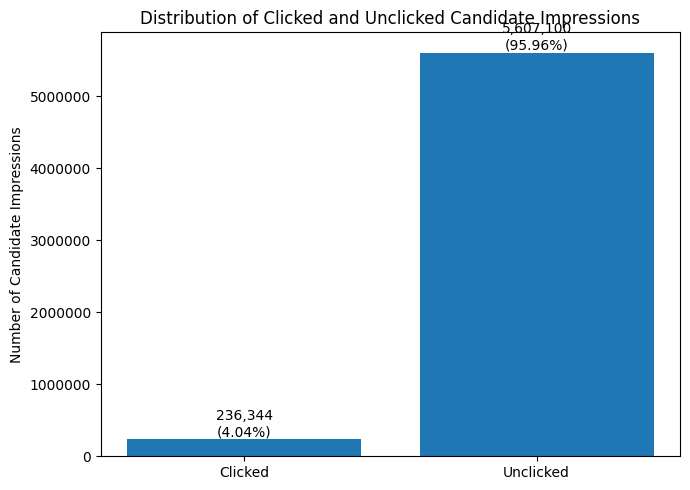

In [24]:
import matplotlib.pyplot as plt

clicked = behaviours["num_clicked"].sum()
unclicked = behaviours["num_unclicked"].sum()

labels = ["Clicked", "Unclicked"]
counts = [clicked, unclicked]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(labels, counts)

ax.set_title("Distribution of Clicked and Unclicked Candidate Impressions")
ax.set_ylabel("Number of Candidate Impressions")

# Add counts and percentages above bars
total = sum(counts)

for bar, count in zip(bars, counts):
    percentage = count / total * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

# Makes large numbers easier to read
ax.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

### History & candidate distribution analysis

In [25]:
display(
    behaviours[
        [
            "history_length",
            "num_candidates",
            "num_clicked"
        ]
    ].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

,history_length,num_candidates,num_clicked
count,156965.000000,156965.000000,156965.000000
mean,32.539987,37.227688,1.505711
std,40.267607,38.594148,1.153102
min,0.000000,2.000000,1.000000
25%,8.000000,10.000000,1.000000
50%,19.000000,24.000000,1.000000
75%,42.000000,51.000000,2.000000
90%,78.000000,91.000000,3.000000
95%,109.000000,118.000000,4.000000
99%,190.000000,166.000000,6.000000


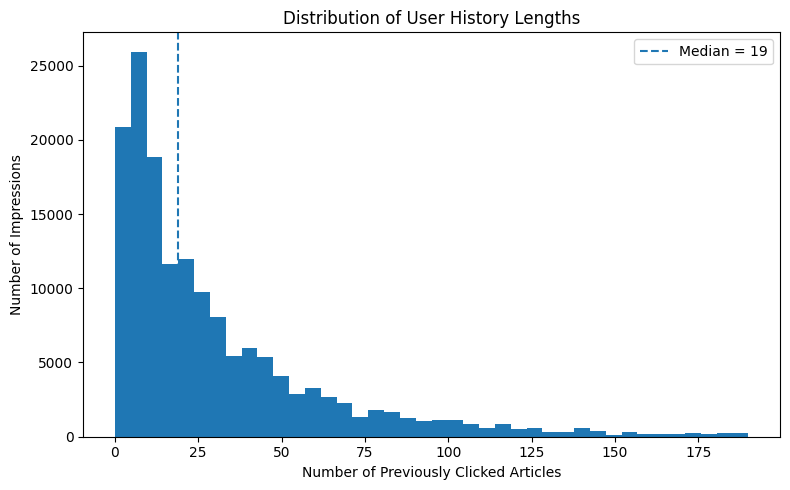

In [26]:
history_99 = behaviours["history_length"].quantile(0.99)
history_median = behaviours["history_length"].median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    behaviours.loc[
        behaviours["history_length"] <= history_99,
        "history_length"
    ],
    bins=40
)

ax.axvline(
    history_median,
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {history_median:.0f}"
)

ax.set_title("Distribution of User History Lengths")
ax.set_xlabel("Number of Previously Clicked Articles")
ax.set_ylabel("Number of Impressions")
ax.legend()

plt.tight_layout()
plt.show()

### News category distributions

In [27]:
print("Number of categories:",
      news["category"].nunique())

print("Number of subcategories:",
      news["subcategory"].nunique())

display(
    news["category"]
    .value_counts()
    .to_frame("count")
)

display(
    news["subcategory"]
    .value_counts()
    .head(20)
    .to_frame("count")
)

Number of categories: 17
Number of subcategories: 264


,count
category,
news,15774
sports,14510
finance,3107
foodanddrink,2551
lifestyle,2479
travel,2350
video,2068
weather,2048
health,1885


,count
subcategory,
newsus,6564
football_nfl,5420
newspolitics,2826
newscrime,2254
weathertopstories,2047
newsworld,1720
football_ncaa,1665
baseball_mlb,1661
basketball_nba,1555


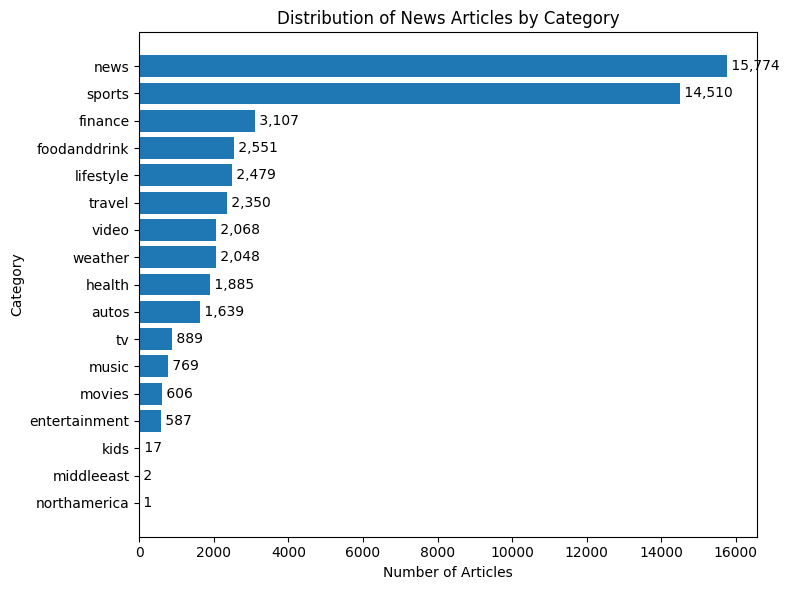

In [28]:
category_counts = (
    news["category"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.barh(
    category_counts.index,
    category_counts.values
)

ax.set_title("Distribution of News Articles by Category")
ax.set_xlabel("Number of Articles")
ax.set_ylabel("Category")

# Add count labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f" {int(width):,}",
        va="center"
    )

plt.tight_layout()
plt.show()

### News text quality

In [29]:
display(
    news[
        [
            "title_length",
            "abstract_length",
            "num_title_entities",
            "num_abstract_entities"
        ]
    ].describe()
)

,title_length,abstract_length,num_title_entities,num_abstract_entities
count,51282.000000,51282.000000,51282.000000,51282.000000
mean,10.754417,34.293319,1.168987,1.858527
std,3.265311,26.542819,0.977183,1.822684
min,1.000000,0.000000,0.000000,0.000000
25%,9.000000,15.000000,0.000000,0.000000
50%,10.000000,24.000000,1.000000,1.000000
75%,13.000000,62.000000,2.000000,3.000000
max,57.000000,474.000000,8.000000,30.000000


In [30]:
print(
    "Empty/missing titles:",
    news["title"].fillna("").str.strip().eq("").sum()
)

print(
    "Empty/missing abstracts:",
    news["abstract"].fillna("").str.strip().eq("").sum()
)

Empty/missing titles: 0
Empty/missing abstracts: 2666


### Check malformed entity JSON

In [31]:
invalid_title_json = (
    news["title_entities_parsed"]
    .apply(lambda x: x is None)
    .sum()
)

invalid_abstract_json = (
    news["abstract_entities_parsed"]
    .apply(lambda x: x is None)
    .sum()
)

print(
    "Malformed title entity JSON:",
    invalid_title_json
)

print(
    "Malformed abstract entity JSON:",
    invalid_abstract_json
)

Malformed title entity JSON: 0
Malformed abstract entity JSON: 0


### Referential integrity betewen behaviours and news

In [32]:
behaviour_news_ids = set()

# IDs appearing in user histories
for history in behaviours["history"].dropna():
    behaviour_news_ids.update(history.split())

# IDs appearing in candidate impressions
for impressions in behaviours["impressions"].dropna():

    for token in impressions.split():
        news_id = token.rsplit("-", 1)[0]
        behaviour_news_ids.add(news_id)

news_ids = set(news["news_id"])

missing_from_news = (
    behaviour_news_ids - news_ids
)

print(
    "Unique news IDs referenced in behaviours:",
    len(behaviour_news_ids)
)

print(
    "Referenced IDs absent from news.tsv:",
    len(missing_from_news)
)

Unique news IDs referenced in behaviours: 51282
Referenced IDs absent from news.tsv: 0


### Check entity-embedding coverage

In [33]:
def extract_wikidata_ids(entity_list):

    if not isinstance(entity_list, list):
        return []

    return [
        entity["WikidataId"]
        for entity in entity_list
        if "WikidataId" in entity
    ]

In [34]:
news["title_wikidata_ids"] = (
    news["title_entities_parsed"]
    .apply(extract_wikidata_ids)
)

news["abstract_wikidata_ids"] = (
    news["abstract_entities_parsed"]
    .apply(extract_wikidata_ids)
)

In [35]:
news_entity_ids = set()

for ids in news["title_wikidata_ids"]:
    news_entity_ids.update(ids)

for ids in news["abstract_wikidata_ids"]:
    news_entity_ids.update(ids)

embedding_entity_ids = set(
    entity_embeddings["entity_id"]
)

entities_without_embedding = (
    news_entity_ids - embedding_entity_ids
)

print(
    "Unique entities referenced in news:",
    len(news_entity_ids)
)

print(
    "Entities with embeddings:",
    len(news_entity_ids & embedding_entity_ids)
)

print(
    "Entities without embeddings:",
    len(entities_without_embedding)
)

if len(news_entity_ids) > 0:
    print(
        "Entity embedding coverage:",
        f"{len(news_entity_ids & embedding_entity_ids) / len(news_entity_ids):.2%}"
    )

Unique entities referenced in news: 27759
Entities with embeddings: 26902
Entities without embeddings: 857
Entity embedding coverage: 96.91%


### Embedding quality

In [36]:
def check_embedding_quality(df, id_col):

    embedding_cols = [
        col for col in df.columns
        if col != id_col
    ]

    values = df[embedding_cols].to_numpy()

    return pd.Series({
        "rows": len(df),
        "dimensions": len(embedding_cols),
        "duplicate_ids": df[id_col].duplicated().sum(),
        "missing_values":
            df[embedding_cols].isna().sum().sum(),
        "non_finite_values":
            (~np.isfinite(values)).sum()
    })

In [37]:
embedding_quality = pd.DataFrame({
    "entity_embedding": check_embedding_quality(
        entity_embeddings,
        "entity_id"
    ),
    "relation_embedding": check_embedding_quality(
        relation_embeddings,
        "relation_id"
    )
}).T

display(embedding_quality)

,rows,dimensions,duplicate_ids,missing_values,non_finite_values
entity_embedding,26904,100,0,0,0
relation_embedding,1091,100,0,0,0


## Summary

In [38]:
dataset_summary = pd.DataFrame({
    "Dataset": [
        "Behaviors",
        "News",
        "Entity embeddings",
        "Relation embeddings"
    ],
    "Rows": [
        len(behaviours),
        len(news),
        len(entity_embeddings),
        len(relation_embeddings)
    ],
    "Columns": [
        len(behaviour_cols),
        len(news_cols),
        entity_embeddings.shape[1],
        relation_embeddings.shape[1]
    ]
})

display(dataset_summary)

,Dataset,Rows,Columns
0,Behaviors,156965,5
1,News,51282,8
2,Entity embeddings,26904,101
3,Relation embeddings,1091,101


In [39]:
feature_metadata = pd.DataFrame([
    {
        "Feature": "impression_id",
        "Source": "behaviors.tsv",
        "Description": "Identifier for an impression/recommendation event",
        "Data type / unit": "Identifier",
        "Status": "Raw"
    },
    {
        "Feature": "user_id",
        "Source": "behaviors.tsv",
        "Description": "Anonymised user identifier",
        "Data type / unit": "Categorical identifier",
        "Status": "Raw"
    },
    {
        "Feature": "time",
        "Source": "behaviors.tsv",
        "Description": "Timestamp of the impression event",
        "Data type / unit": "Datetime",
        "Status": "Raw"
    },
    {
        "Feature": "history",
        "Source": "behaviors.tsv",
        "Description": "Previously clicked news articles",
        "Data type / unit": "Sequence of news IDs",
        "Status": "Raw"
    },
    {
        "Feature": "category",
        "Source": "news.tsv",
        "Description": "Top-level news category",
        "Data type / unit": "Categorical",
        "Status": "Raw"
    },
    {
        "Feature": "subcategory",
        "Source": "news.tsv",
        "Description": "News subcategory",
        "Data type / unit": "Categorical",
        "Status": "Raw"
    },
    {
        "Feature": "title",
        "Source": "news.tsv",
        "Description": "Article headline",
        "Data type / unit": "Text",
        "Status": "Raw"
    },
    {
        "Feature": "abstract",
        "Source": "news.tsv",
        "Description": "Article summary",
        "Data type / unit": "Text",
        "Status": "Raw"
    },
    {
        "Feature": "history_length",
        "Source": "behaviors.tsv",
        "Description": "Number of previously clicked articles",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "num_candidates",
        "Source": "behaviors.tsv",
        "Description": "Number of candidate articles in an impression",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "num_clicked",
        "Source": "behaviors.tsv",
        "Description": "Number of clicked candidates in an impression",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "num_unclicked",
        "Source": "behaviors.tsv",
        "Description": "Number of exposed but unclicked candidates",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "title_length",
        "Source": "news.tsv",
        "Description": "Number of words in article title",
        "Data type / unit": "Words",
        "Status": "Derived"
    },
    {
        "Feature": "abstract_length",
        "Source": "news.tsv",
        "Description": "Number of words in article abstract",
        "Data type / unit": "Words",
        "Status": "Derived"
    },
    {
        "Feature": "num_title_entities",
        "Source": "news.tsv",
        "Description": "Number of entities identified in title",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "num_abstract_entities",
        "Source": "news.tsv",
        "Description": "Number of entities identified in abstract",
        "Data type / unit": "Count",
        "Status": "Derived"
    },
    {
        "Feature": "entity_embedding",
        "Source": "entity_embedding.vec",
        "Description": "Pretrained representation of Wikidata entity",
        "Data type / unit": "100-dimensional vector",
        "Status": "Raw / pretrained"
    },
    {
        "Feature": "title_abstract_tfidf",
        "Source": "news.tsv",
        "Description": "TF-IDF representation of article textual content",
        "Data type / unit": "Numeric vector",
        "Status": "Proposed"
    },
    {
        "Feature": "historical_popularity_ctr",
        "Source": "behaviors.tsv",
        "Description": "Article popularity/click-through signal computed using prior interactions only",
        "Data type / unit": "Count / proportion",
        "Status": "Proposed"
    }
])

display(feature_metadata)

,Feature,Source,Description,Data type / unit,Status
0,impression_id,behaviors.tsv,Identifier for an impression/recommendation event,Identifier,Raw
1,user_id,behaviors.tsv,Anonymised user identifier,Categorical identifier,Raw
2,time,behaviors.tsv,Timestamp of the impression event,Datetime,Raw
3,history,behaviors.tsv,Previously clicked news articles,Sequence of news IDs,Raw
4,category,news.tsv,Top-level news category,Categorical,Raw
5,subcategory,news.tsv,News subcategory,Categorical,Raw
6,title,news.tsv,Article headline,Text,Raw
7,abstract,news.tsv,Article summary,Text,Raw
8,history_length,behaviors.tsv,Number of previously clicked articles,Count,Derived
9,num_candidates,behaviors.tsv,Number of candidate articles in an impression,Count,Derived


In [40]:
numeric_features = {
    "history_length": behaviours["history_length"],
    "num_candidates": behaviours["num_candidates"],
    "num_clicked": behaviours["num_clicked"],
    "num_unclicked": behaviours["num_unclicked"],
    "title_length": news["title_length"],
    "abstract_length": news["abstract_length"],
    "num_title_entities": news["num_title_entities"],
    "num_abstract_entities": news["num_abstract_entities"]
}

numeric_summary = []

for feature, series in numeric_features.items():
    numeric_summary.append({
        "Feature": feature,
        "Min": series.min(),
        "Max": series.max(),
        "Mean": series.mean(),
        "Median": series.median(),
        "Std. Dev.": series.std(),
        "Missing": series.isna().sum()
    })

numeric_summary = pd.DataFrame(numeric_summary)

# Make table easier to read
numeric_summary[
    ["Mean", "Median", "Std. Dev."]
] = numeric_summary[
    ["Mean", "Median", "Std. Dev."]
].round(2)

display(numeric_summary)

,Feature,Min,Max,Mean,Median,Std. Dev.,Missing
0,history_length,0,558,32.54,19.0,40.27,0
1,num_candidates,2,299,37.23,24.0,38.59,0
2,num_clicked,1,35,1.51,1.0,1.15,0
3,num_unclicked,1,297,35.72,23.0,38.15,0
4,title_length,1,57,10.75,10.0,3.27,0
5,abstract_length,0,474,34.29,24.0,26.54,0
6,num_title_entities,0,8,1.17,1.0,0.98,0
7,num_abstract_entities,0,30,1.86,1.0,1.82,0


4.2 Interaction Hierarchy & Funnel

In [41]:
# Funnel for MINDsmall_train: exposure -> click


total_impressions = len(behaviours)
total_exposures = behaviours["num_candidates"].sum()
total_clicks = behaviours["num_clicked"].sum()

overall_click_rate = total_clicks / total_exposures

funnel = pd.DataFrame({
    "Stage": ["Exposure (candidate shown)", "Click"],
    "Count": [total_exposures, total_clicks],
    "% of exposures": [100.0, overall_click_rate * 100]
})

print("Total impressions (sessions):", f"{total_impressions:,}")
print("Total candidate exposures:", f"{total_exposures:,}")
print("Total clicks:", f"{total_clicks:,}")
print(f"Overall click rate: {overall_click_rate:.4f} ({overall_click_rate * 100:.2f}%)")

display(funnel)

Total impressions (sessions): 156,965
Total candidate exposures: 5,843,444
Total clicks: 236,344
Overall click rate: 0.0404 (4.04%)


,Stage,Count,% of exposures
0,Exposure (candidate shown),5843444,100.000000
1,Click,236344,4.044601


In [42]:
# Distribution of clicks per impression
clicks_per_impression = (
    behaviours["num_clicked"]
    .value_counts()
    .sort_index()
    .to_frame("num_impressions")
)

clicks_per_impression["pct_impressions"] = (
    clicks_per_impression["num_impressions"] / total_impressions * 100
)

clicks_per_impression.index.name = "clicks_in_impression"

display(
    behaviours["num_clicked"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

display(clicks_per_impression)

,num_clicked
count,156965.000000
mean,1.505711
std,1.153102
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
90%,3.000000
95%,4.000000
99%,6.000000


,num_impressions,pct_impressions
clicks_in_impression,,
1,113888,72.556302
2,25571,16.290893
3,9263,5.901316
4,3975,2.532412
5,1957,1.246775
6,942,0.600134
7,515,0.328099
8,296,0.188577
9,198,0.126143


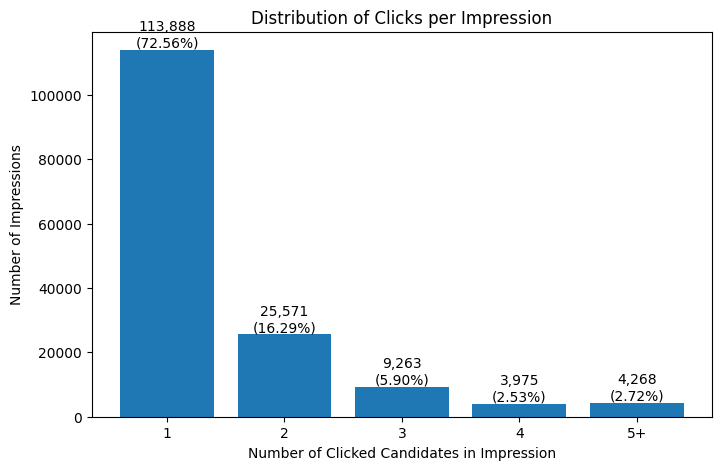

In [43]:
# Group long tail into a "5+" bucket for readability
click_buckets = (
    behaviours["num_clicked"]
    .clip(upper=5)
    .value_counts()
    .sort_index()
)

bucket_labels = [
    "5+" if k == 5 else str(k)
    for k in click_buckets.index
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(bucket_labels, click_buckets.values)

for bar, count in zip(bars, click_buckets.values):
    percentage = count / total_impressions * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Distribution of Clicks per Impression")
ax.set_xlabel("Number of Clicked Candidates in Impression")
ax.set_ylabel("Number of Impressions")

ax.ticklabel_format(
    style="plain",
    axis="y"
)
plt.show()

## 4.4 Sparsity & Temporal Patterns

Run the existing loading and parsing cells first. These cells use `behaviours` (British spelling) and `news`; they do not modify those dataframes or source files.

Scope: the currently loaded, **unsampled** source split. For this notebook, use the original **MINDsmall_train** (all 9–14 November events), before your group's further chronological split. Keep the reserved final evaluation set separate.

We examine supplied history lengths per impression, article exposure/click concentration, and gaps between each user's logged impressions. These descriptive measures are not a user–article matrix density estimate. Histories are not lifetime activity records, and impression gaps are not intervals between individual clicks.


In [44]:
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

s44_required = [
    "impression_id", "user_id", "time_parsed", "history_length",
    "parsed_impressions", "num_candidates", "num_clicked",
]
s44_missing = sorted(set(s44_required) - set(behaviours.columns))
if s44_missing:
    raise ValueError(f"Run the earlier parsing cells first. Missing columns: {s44_missing}")
s44 = behaviours[s44_required].copy()
if s44.empty:
    raise ValueError("The loaded behaviours table is empty.")
if s44[["impression_id", "user_id", "time_parsed", "history_length"]].isna().any().any():
    raise ValueError("Resolve missing IDs, invalid timestamps or unparsed history lengths first.")
if s44["impression_id"].duplicated().any():
    raise ValueError("Repeated impression IDs found. Review duplicates before counting events.")
if (s44["history_length"] < 0).any():
    raise ValueError("History lengths cannot be negative.")

s44_scope = Path(DATA_DIR).name if "DATA_DIR" in globals() else "loaded source split"
print(f"Scope: {s44_scope} — use unsampled impressions")
print(f"{len(s44):,} impressions; {s44['user_id'].nunique():,} distinct users")
print(f"Recorded time range: {s44['time_parsed'].min()} to {s44['time_parsed'].max()}")


Scope: MINDsmall_train — use unsampled impressions
156,965 impressions; 50,000 distinct users
Recorded time range: 2019-11-09 00:00:19 to 2019-11-14 23:59:13


### 4.4.1 Supplied click-history lengths

Each observation is the history available at one impression. Frequent users contribute more observations: this is **not** a distribution with one observation per user. Empty histories indicate no supplied prior clicks for that event, not necessarily no lifetime activity.

Also summarize logged impressions per user. The histogram includes zero and the full history-length range; its vertical axis uses a logarithmic scale.


,History length per impression,Logged impressions per user
count,156965.00,50000.00
mean,32.54,3.14
std,40.27,3.00
min,0.00,1.00
25%,8.00,1.00
50%,19.00,2.00
75%,42.00,4.00
90%,78.00,6.00
95%,109.00,9.00
99%,190.00,15.00


Empty supplied histories: 3,238 / 156,965 impressions (2.06%)


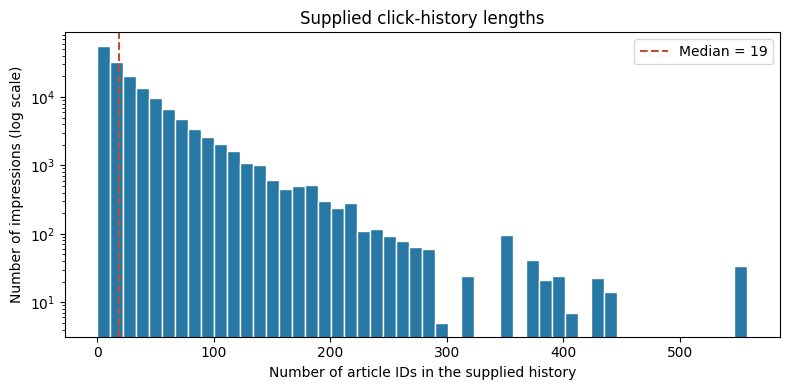

In [45]:
s44_history = s44["history_length"]
s44_impressions_per_user = s44.groupby("user_id").size()
s44_history_summary = pd.DataFrame({
    "History length per impression": s44_history.describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]),
    "Logged impressions per user": s44_impressions_per_user.describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]),
})
s44_empty_histories = int(s44_history.eq(0).sum())
s44_empty_history_pct = 100 * s44_empty_histories / len(s44)
display(s44_history_summary.round(2))
print(f"Empty supplied histories: {s44_empty_histories:,} / {len(s44):,} impressions "
      f"({s44_empty_history_pct:.2f}%)")

s44_fig_history, ax = plt.subplots(figsize=(8, 4))
ax.hist(s44_history, bins=50, color="#2878A5", edgecolor="white", log=True)
ax.axvline(s44_history.median(), color="#C04D33", linestyle="--",
           label=f"Median = {s44_history.median():g}")
ax.set(title="Supplied click-history lengths",
       xlabel="Number of article IDs in the supplied history",
       ylabel="Number of impressions (log scale)")
ax.legend()
s44_fig_history.tight_layout()
plt.show()


### 4.4.2 Article popularity: head versus long tail

Count candidate entries as exposures and label-1 entries as clicks. Do **not** add history entries to these click counts: histories recur across impressions and describe earlier activity.

Concentration uses all distinct **exposed articles**, including zero-click articles. Metadata-only articles are reported separately; their presence does not establish availability for every impression.

Exposure and click curves rank articles **separately**, so their “top 10%” groups may differ. Round fractions up to a whole article and report the actual count.


,Value
Distinct exposed articles,20288.00
Distinct articles with at least one click,7713.00
Exposed articles with zero clicks,12575.00
Zero-click share of exposed articles (%),61.98
Metadata articles with no recorded exposure,30994.00
Exposed articles missing from news metadata,0.00


,Number of articles,Actual article share (%),"Exposure share (ranked by exposures, %)","Click share (ranked by clicks, %)"
Top fraction,,,,
1%,203,1.0,32.52,51.67
10%,2029,10.0,90.54,93.52
20%,4058,20.0,97.51,98.11


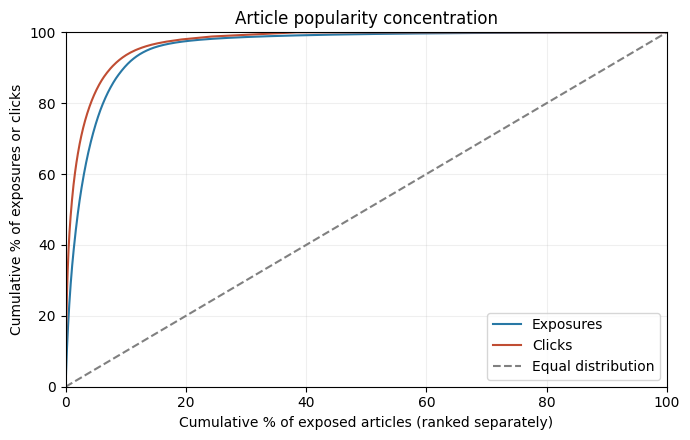

Curves rising more sharply above the diagonal indicate greater concentration.
Click counts also reflect exposure opportunities; they are not pure preference measures.


In [46]:
s44_exposure_counts, s44_click_counts = Counter(), Counter()
# Count directly from parsed lists; no large candidate-level dataframe is needed.
for candidates in s44["parsed_impressions"]:
    for candidate in candidates:
        article_id, label = candidate["news_id"], candidate["label"]
        if label not in (0, 1):
            raise ValueError(f"Unexpected click label: {label!r}")
        if pd.isna(article_id) or str(article_id).strip() == "":
            raise ValueError("A candidate is missing its article ID.")
        s44_exposure_counts[article_id] += 1
        if label == 1:
            s44_click_counts[article_id] += 1
if not s44_exposure_counts:
    raise ValueError("No candidate exposures were found.")

s44_total_exposures = sum(s44_exposure_counts.values())
s44_total_clicks = sum(s44_click_counts.values())
assert s44_total_exposures == int(s44["num_candidates"].sum()), "Exposure totals disagree."
assert s44_total_clicks == int(s44["num_clicked"].sum()), "Click totals disagree."

s44_metadata_ids = set(news["news_id"].dropna())
s44_all_ids = sorted(s44_metadata_ids | set(s44_exposure_counts))
s44_article_counts = pd.DataFrame({
    "news_id": s44_all_ids,
    "exposures": [s44_exposure_counts[x] for x in s44_all_ids],
    "clicks": [s44_click_counts[x] for x in s44_all_ids],
    "has_metadata": [x in s44_metadata_ids for x in s44_all_ids],
})
s44_exposed_articles = s44_article_counts.loc[s44_article_counts["exposures"] > 0].copy()
s44_n_articles = len(s44_exposed_articles)
s44_zero_click_articles = int(s44_exposed_articles["clicks"].eq(0).sum())
s44_popularity_summary = pd.Series({
    "Distinct exposed articles": s44_n_articles,
    "Distinct articles with at least one click": int(s44_exposed_articles["clicks"].gt(0).sum()),
    "Exposed articles with zero clicks": s44_zero_click_articles,
    "Zero-click share of exposed articles (%)": 100 * s44_zero_click_articles / s44_n_articles,
    "Metadata articles with no recorded exposure": int(
        ((s44_article_counts["exposures"] == 0) & s44_article_counts["has_metadata"]).sum()),
    "Exposed articles missing from news metadata": int(
        (~s44_exposed_articles["has_metadata"]).sum()),
}, name="Value").to_frame()
display(s44_popularity_summary.round(2))

s44_concentration_rows = []
for fraction in (0.01, 0.10, 0.20):
    k = max(1, int(np.ceil(fraction * s44_n_articles)))
    s44_concentration_rows.append({
        "Top fraction": f"{fraction:.0%}",
        "Number of articles": k,
        "Actual article share (%)": 100 * k / s44_n_articles,
        "Exposure share (ranked by exposures, %)":
            100 * s44_exposed_articles["exposures"].nlargest(k).sum() / s44_total_exposures,
        "Click share (ranked by clicks, %)":
            (100 * s44_exposed_articles["clicks"].nlargest(k).sum() / s44_total_clicks)
            if s44_total_clicks else np.nan,
    })
s44_concentration = pd.DataFrame(s44_concentration_rows).set_index("Top fraction")
display(s44_concentration.round(2))

s44_fig_popularity, ax = plt.subplots(figsize=(7, 4.5))
s44_rank_pct = np.arange(s44_n_articles + 1) / s44_n_articles * 100
for column, color in [("exposures", "#2878A5"), ("clicks", "#C04D33")]:
    counts = s44_exposed_articles[column].sort_values(ascending=False).to_numpy()
    if counts.sum() > 0:
        ax.plot(s44_rank_pct, np.r_[0, counts.cumsum() / counts.sum() * 100],
                label=column.capitalize(), color=color)
ax.plot([0, 100], [0, 100], "--", color="gray", label="Equal distribution")
ax.set(title="Article popularity concentration",
       xlabel="Cumulative % of exposed articles (ranked separately)",
       ylabel="Cumulative % of exposures or clicks", xlim=(0, 100), ylim=(0, 100))
ax.legend()
ax.grid(alpha=0.2)
s44_fig_popularity.tight_layout()
plt.show()
print("Curves rising more sharply above the diagonal indicate greater concentration.")
print("Click counts also reflect exposure opportunities; they are not pure preference measures.")


### 4.4.3 Time gaps between consecutive logged impressions

Sort impressions by user and timestamp, then subtract each user's preceding impression time. Exclude each user's first impression because it has no preceding event in this file. Users with one impression contribute no gaps.

Keep zero gaps for same-timestamp events in summary statistics. The logarithmic histogram shows only positive gaps and states how many zeros it omits. These gaps do not measure intervals between historical clicks, reading duration, or events outside this observation window.


,Gap between consecutive impressions (hours)
count,106965.0000
mean,18.3149
std,20.7531
min,0.0000
25%,2.1475
50%,12.8158
75%,24.7619
90%,47.4497
95%,60.3508
99%,95.4960


Users with at least two logged impressions: 33,617
Users with only one logged impression: 16,383
Eligible within-user gaps: 106,965
Zero-hour gaps (included in statistics): 17 (0.02%)


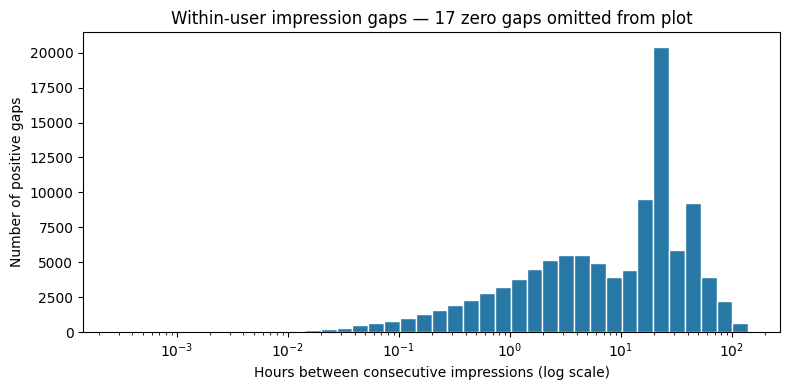

In [47]:
s44_ordered = s44.sort_values(["user_id", "time_parsed"], kind="stable")
s44_gap_hours = (
    s44_ordered.groupby("user_id", sort=False)["time_parsed"]
    .diff().dt.total_seconds().div(3600).dropna()
)
assert len(s44_gap_hours) == len(s44) - s44["user_id"].nunique()
assert s44_gap_hours.ge(0).all()
s44_zero_gaps = int(s44_gap_hours.eq(0).sum())
s44_positive_gaps = s44_gap_hours.loc[s44_gap_hours > 0]
s44_gap_summary = s44_gap_hours.describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
).to_frame("Gap between consecutive impressions (hours)")
display(s44_gap_summary.round(4))
print(f"Users with at least two logged impressions: {s44_impressions_per_user.ge(2).sum():,}")
print(f"Users with only one logged impression: {s44_impressions_per_user.eq(1).sum():,}")
print(f"Eligible within-user gaps: {len(s44_gap_hours):,}")
if len(s44_gap_hours):
    print(f"Zero-hour gaps (included in statistics): {s44_zero_gaps:,} "
          f"({100 * s44_zero_gaps / len(s44_gap_hours):.2f}%)")

s44_fig_gaps, ax = plt.subplots(figsize=(8, 4))
if len(s44_positive_gaps):
    lo, hi = s44_positive_gaps.min(), s44_positive_gaps.max()
    if lo == hi:
        lo, hi = lo / 2, hi * 2
    ax.hist(s44_positive_gaps, bins=np.geomspace(lo, hi, 41),
            color="#2878A5", edgecolor="white")
    ax.set_xscale("log")
    ax.set_xlabel("Hours between consecutive impressions (log scale)")
    ax.set_ylabel("Number of positive gaps")
else:
    ax.text(0.5, 0.5, "No positive within-user gaps in this data.",
            ha="center", va="center", transform=ax.transAxes)
ax.set_title(f"Within-user impression gaps — {s44_zero_gaps:,} zero gaps omitted from plot")
s44_fig_gaps.tight_layout()
plt.show()


### Report paragraph using your calculated results

The next cell generates a concise paragraph for Section 4.4. Read it alongside the graphs; it reports measured values without assuming strong concentration in advance.

These analyses can motivate checking performance for users with limited histories and less popular articles. Content features, missing-history handling and a popularity baseline are possible responses; EDA alone does not prove that they improve ranking.


In [48]:
s44_top10 = s44_concentration.loc["10%"]
s44_exposure_share = s44_top10["Exposure share (ranked by exposures, %)"]
s44_click_share = s44_top10["Click share (ranked by clicks, %)"]
s44_report = (
    f"In {s44_scope}, supplied click histories had a median length of "
    f"{s44_history.median():g} articles (mean {s44_history.mean():.2f}; "
    f"range {s44_history.min():.0f}–{s44_history.max():.0f}). "
    f"Empty histories occurred in {s44_empty_history_pct:.2f}% of impressions. "
    "These statistics are measured per impression, so users with more impressions "
    "contribute more observations. "
    f"Among {s44_n_articles:,} exposed articles, the top 10% ranked by exposure "
    f"accounted for {s44_exposure_share:.2f}% of candidate exposures"
)
if pd.notna(s44_click_share):
    s44_report += (
        f"; the top 10% ranked separately by clicks accounted for "
        f"{s44_click_share:.2f}% of clicks. "
    )
else:
    s44_report += "; no clicks were recorded in this data. "
s44_report += (
    f"{100 * s44_zero_click_articles / s44_n_articles:.2f}% of exposed articles "
    "received no clicks within the observation window. "
)
if len(s44_gap_hours):
    s44_report += (
        f"Across {len(s44_gap_hours):,} consecutive within-user impression pairs, "
        f"the median gap was {s44_gap_hours.median():.2f} hours "
        f"(90th percentile: {s44_gap_hours.quantile(0.90):.2f} hours), "
        f"including {s44_zero_gaps:,} zero-length gaps. "
    )
else:
    s44_report += "No user had enough recorded impressions to calculate a time gap. "
s44_report += (
    "These gaps describe logged impressions, not individual clicks or reading time. "
    "The findings inform missing-history handling and evaluation across user-history "
    "lengths and article popularity levels."
)
display(Markdown(s44_report))


In MINDsmall_train, supplied click histories had a median length of 19 articles (mean 32.54; range 0–558). Empty histories occurred in 2.06% of impressions. These statistics are measured per impression, so users with more impressions contribute more observations. Among 20,288 exposed articles, the top 10% ranked by exposure accounted for 90.54% of candidate exposures; the top 10% ranked separately by clicks accounted for 93.52% of clicks. 61.98% of exposed articles received no clicks within the observation window. Across 106,965 consecutive within-user impression pairs, the median gap was 12.82 hours (90th percentile: 47.45 hours), including 17 zero-length gaps. These gaps describe logged impressions, not individual clicks or reading time. The findings inform missing-history handling and evaluation across user-history lengths and article popularity levels.

### Optional: save figures and summary tables

Set `S44_SAVE_OUTPUTS = True` to save PNGs, CSV summaries and the generated paragraph. The default folder is relative to the runtime. Set it to a Drive folder if you want the files to persist after Colab disconnects. Raw source files remain untouched.


In [49]:
S44_SAVE_OUTPUTS = False
S44_OUTPUT_DIR = Path("outputs/section_4_4")
if S44_SAVE_OUTPUTS:
    S44_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name, figure in [
        ("history_lengths", s44_fig_history),
        ("article_popularity", s44_fig_popularity),
        ("impression_gaps", s44_fig_gaps),
    ]:
        figure.savefig(S44_OUTPUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    s44_history_summary.to_csv(S44_OUTPUT_DIR / "history_and_user_activity.csv")
    s44_popularity_summary.to_csv(S44_OUTPUT_DIR / "article_popularity_summary.csv")
    s44_concentration.to_csv(S44_OUTPUT_DIR / "popularity_concentration.csv")
    s44_gap_summary.to_csv(S44_OUTPUT_DIR / "impression_gap_summary.csv")
    (S44_OUTPUT_DIR / "report_paragraph.txt").write_text(s44_report, encoding="utf-8")
    print(f"Saved outputs to: {S44_OUTPUT_DIR.resolve()}")
